# 01 · Perceptron

The smallest neural network: **one neuron**, a weighted sum and a hard threshold. Numpy only.

$$z = \mathbf{w}\cdot\mathbf{x} + b, \qquad \hat y = \begin{cases}1 & z \ge 0\\ 0 & z < 0\end{cases}$$

**Rosenblatt learning rule** — only update on mistakes:

$$\mathbf{w} \leftarrow \mathbf{w} + \eta\,(y - \hat y)\,\mathbf{x}, \qquad b \leftarrow b + \eta\,(y - \hat y)$$

If the prediction is right, $(y-\hat y)=0$ and nothing changes. If it's wrong, the weight vector is nudged toward (or away from) the input, rotating the decision line.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## The model

In [2]:
class Perceptron:
    """Rosenblatt perceptron: single neuron, step activation, mistake-driven update."""

    def __init__(self, input_size, learning_rate=0.1):
        self.weights = np.zeros(input_size)
        self.bias = 0.0
        self.lr = learning_rate

    def step(self, z):
        return (z >= 0).astype(int)

    def predict(self, X):
        return self.step(np.dot(X, self.weights) + self.bias)

    def fit(self, X, y, epochs=20):
        for _ in range(epochs):
            errors = 0
            for xi, target in zip(X, y):
                pred = self.step(np.dot(xi, self.weights) + self.bias)
                error = target - pred
                if error != 0:
                    self.weights += self.lr * error * xi
                    self.bias += self.lr * error
                    errors += 1
            if errors == 0:   # a full clean pass: converged
                break
        return self

## Learn AND and OR

Both are **linearly separable**: a single straight line splits the 0s from the 1s. The perceptron convergence theorem guarantees the rule finds such a line in finite steps.

In [3]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
gates = {"AND": np.array([0, 0, 0, 1]),
         "OR":  np.array([0, 1, 1, 1]),
         "XOR": np.array([0, 1, 1, 0])}

models = {}
for name, y in gates.items():
    models[name] = Perceptron(input_size=2).fit(X, y, epochs=50)
    p = models[name]
    print(f"{name:>3}: w={p.weights.round(2)} b={p.bias:.2f}  preds={p.predict(X).tolist()}  target={y.tolist()}")

AND: w=[0.2 0.1] b=-0.20  preds=[0, 0, 0, 1]  target=[0, 0, 0, 1]
 OR: w=[0.1 0.1] b=-0.10  preds=[0, 1, 1, 1]  target=[0, 1, 1, 1]
XOR: w=[-0.1  0. ] b=0.00  preds=[1, 1, 0, 0]  target=[0, 1, 1, 0]


In [4]:
assert np.array_equal(models["AND"].predict(X), gates["AND"]), "failed to learn AND"
assert np.array_equal(models["OR"].predict(X), gates["OR"]), "failed to learn OR"

## Decision boundaries

The learned line is $w_1x_1 + w_2x_2 + b = 0$. Try changing `learning_rate` or `epochs` above and re-run to see how the line moves.

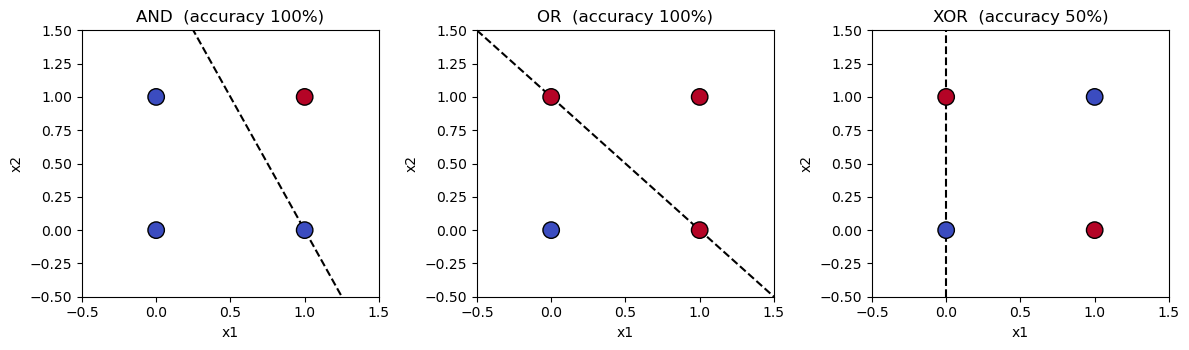

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
xs = np.linspace(-0.5, 1.5, 100)
for ax, (name, y) in zip(axes, gates.items()):
    p = models[name]
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=140, edgecolor="k", zorder=3)
    if abs(p.weights[1]) > 1e-9:
        ax.plot(xs, -(p.weights[0] * xs + p.bias) / p.weights[1], "k--")
    elif abs(p.weights[0]) > 1e-9:
        ax.axvline(-p.bias / p.weights[0], color="k", ls="--")
    acc = np.mean(p.predict(X) == y)
    ax.set(title=f"{name}  (accuracy {acc:.0%})", xlim=(-0.5, 1.5), ylim=(-0.5, 1.5), xlabel="x1", ylabel="x2")
plt.tight_layout()
plt.show()

## XOR — the limit of one neuron

XOR needs the points $(0,1),(1,0)$ on one side and $(0,0),(1,1)$ on the other. No single line does that (Minsky & Papert, 1969), so the rule never stops making mistakes and accuracy stays stuck.

That is exactly what a hidden layer fixes → **next: `02_backpropagation`**.

In [6]:
xor_acc = np.mean(models["XOR"].predict(X) == gates["XOR"])
print(f"XOR accuracy: {xor_acc:.0%}")
assert xor_acc < 1.0, "a single perceptron cannot solve XOR"

XOR accuracy: 50%
